# Úkol 3: Klasifikace (Originál vs. Inpainted), Interpretovatelnost (XAI) a Siamské sítě

**Cíle úlohy podle zadání:**
1. **Klasifikace (Originál vs. Inpainted):**
   - Příprava datasetu obsahujícího 2 třídy: originální řasinky a modifikace vzniklé inpaintingem mikrotubulů (OpenCV `cv2.inpaint` - Telea).
   - Návrh a natrénování vlastní CNN architektury.
   - Využití předtrénovaného modelu (Transfer Learning) s páteřní sítí ResNet18.
   - Srovnání výkonnosti (loss křivky, přesnost, matice záměn).
2. **Interpretovatelnost modelu (XAI):**
   - Aplikace atribučních metod (Grad-CAM, Saliency Maps, Integrated Gradients).
   - Vizualizace oblastí, na které se síť zaměřuje při rozlišování mezi originálními a inpaintovanými snímky.
3. **Siamské sítě:**
   - Tvorba pozitivních (stejná třída) a negativních (různé třídy) párů.
   - Implementace Contrastive Loss funkce.
   - Vyhodnocení měření podobnosti a 2D PCA vizualizace naučeného embeddingového prostoru.

In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# # Import podpůrných funkcí z utils3.py
# current_dir = Path.cwd()
# if str(current_dir) not in sys.path:
#     sys.path.insert(0, str(current_dir))

from utils3 import *

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cpu


## 1. Příprava datasetu (Originál vs. Inpainted)

Dataset vychází ze snímků buněk (`Data/cells/`) a bodových masek mikrotubulů (`Data/masks_pts/`).
- Pro každý snímek je vygenerována inpaintovaná varianta odstraněním mikrotubulů pomocí `cv2.inpaint` (algoritmus Telea).
- **Důležité pro validaci:** Rozdělení do trénovací a validační sady probíhá na úrovni buněk (cell ID) v poměru **80 : 20**. Originální snímek i jeho inpaintovaná varianta tak vždy patří do stejného splitu, čímž se striktně zamezuje úniku informací (data leakage) mezi tréninkem a validací.

In [2]:
cells_dir = Path.cwd().resolve().parent / "Data" / "cells"
masks_dir = Path.cwd().resolve().parent / "Data" / "masks_pts"
print(f"Cells: {cells_dir}")
print(f"Masks: {masks_dir}")

train_data, val_data = prepare_classification_dataset(cells_dir, masks_dir, val_ratio=0.2, img_size=128)
print(f"Training samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")

Cells: C:\Users\galem\Documents\FIT-CTU\ANI-PIV\Data\cells
Masks: C:\Users\galem\Documents\FIT-CTU\ANI-PIV\Data\masks_pts
Training samples: 251
Validation samples: 63


### 1.1 Vizualizace vzorků datasetu
Zobrazení originální řasinky, odpovídající masky mikrotubulů, inpaintovaného výsledku a rozdílové mapy.

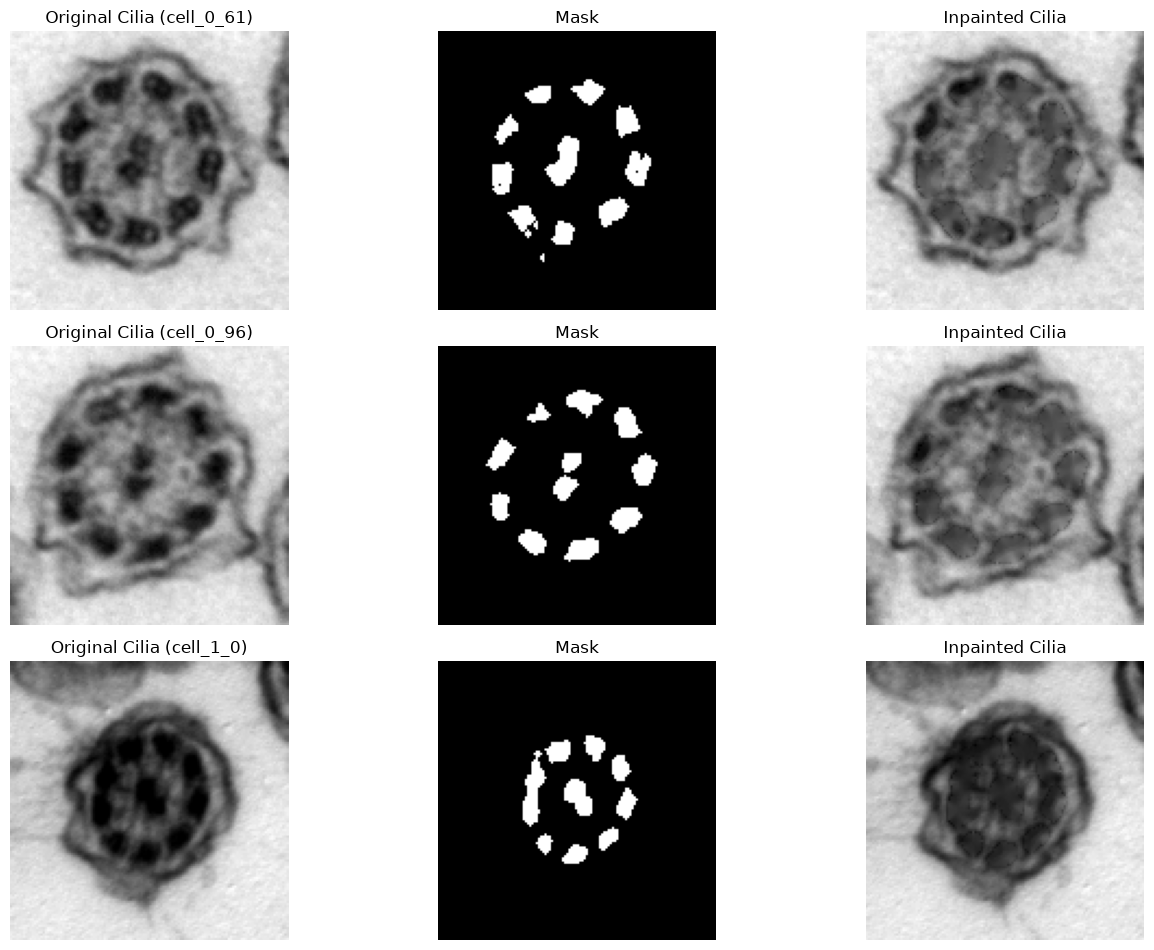

In [3]:
plot_dataset_samples(val_data, num_examples=3)

### 1.2 Vytvoření DataLoaderů
Vytvoříme PyTorch `Dataset` a `DataLoader`. Pro trénovací sadu zapínáme augmentace (náhodné horizontální a vertikální překlopení).

In [4]:
batch_size = 32
train_dataset = CiliaClassificationDataset(train_data, img_size=256, augment=True, to_rgb=True)
val_dataset = CiliaClassificationDataset(val_data, img_size=256, augment=False, to_rgb=True)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

## 2. Klasifikace: Vlastní CNN vs. Předtrénovaný ResNet18

### 2.1 Vlastní konvoluční architektura (Custom CNN)
Navržená architektura obsahuje:
- 4 konvoluční bloky: Conv2d (3x3) -> BatchNorm2d -> ReLU -> MaxPool2d (32 -> 64 -> 128 -> 256 kanálů)
- Adaptivní průměrovací vrstvu (AdaptiveAvgPool2d)
- Klasifikační hlavu: Flatten -> Dropout(0.3) -> Linear(256, 128) -> ReLU -> Dropout(0.3) -> Linear(128, 2)

In [6]:
custom_model = CustomCNN(in_channels=3, num_classes=2, dropout=0.3).to(device)

hist_custom = train_classifier(
    custom_model,
    train_loader,
    val_loader,
    num_epochs=5,
    lr=1e-3,
    device=device
)

Epoch  | Train Loss  | Train Acc  | Val Loss   | Val Acc   
--------------------------------------------------------
1      | 0.5092      | 0.7709     | 0.9208     | 0.5159    
2      | 0.2180      | 0.9402     | 0.9187     | 0.6984    
3      | 0.1402      | 0.9562     | 0.9612     | 0.6667    
4      | 0.1190      | 0.9582     | 1.7881     | 0.6746    
5      | 0.1184      | 0.9681     | 0.2023     | 0.9048    


### 2.2 Předtrénovaný model (Transfer Learning - ResNet18)
Využití páteřní sítě ResNet18 předtrénované na rozsáhlém datasetu ImageNet-1K s upravenou finální vrstvou pro binární klasifikaci.

In [7]:
# 2. ResNet18 – Freeze feature extractor
resnet_frozen = get_pretrained_resnet(num_classes=2, fine_tune=False).to(device)

hist_frozen = train_classifier(
    resnet_frozen, train_loader, val_loader, num_epochs=5, lr=1e-3, device=device)

# 3. ResNet18 – Fine-tune entire model
resnet_finetune = get_pretrained_resnet(num_classes=2, fine_tune=True).to(device)

hist_finetune = train_classifier(
    resnet_finetune, train_loader, val_loader, num_epochs=5, lr=1e-4, device=device)

Epoch  | Train Loss  | Train Acc  | Val Loss   | Val Acc   
--------------------------------------------------------
1      | 0.5912      | 0.6813     | 0.5958     | 0.5794    
2      | 0.3964      | 0.8446     | 0.6829     | 0.5397    
3      | 0.3072      | 0.8904     | 0.7354     | 0.5397    
4      | 0.2817      | 0.9004     | 0.5443     | 0.6667    
5      | 0.2304      | 0.9084     | 0.4999     | 0.7540    
Epoch  | Train Loss  | Train Acc  | Val Loss   | Val Acc   
--------------------------------------------------------
1      | 0.3357      | 0.8625     | 1.6121     | 0.5238    
2      | 0.0393      | 0.9900     | 0.6317     | 0.7937    
3      | 0.0125      | 0.9960     | 0.2688     | 0.9206    
4      | 0.0018      | 1.0000     | 0.1016     | 0.9683    
5      | 0.0037      | 0.9980     | 0.0338     | 0.9921    


### 2.3 Srovnání průběhu trénování (Loss & Accuracy)

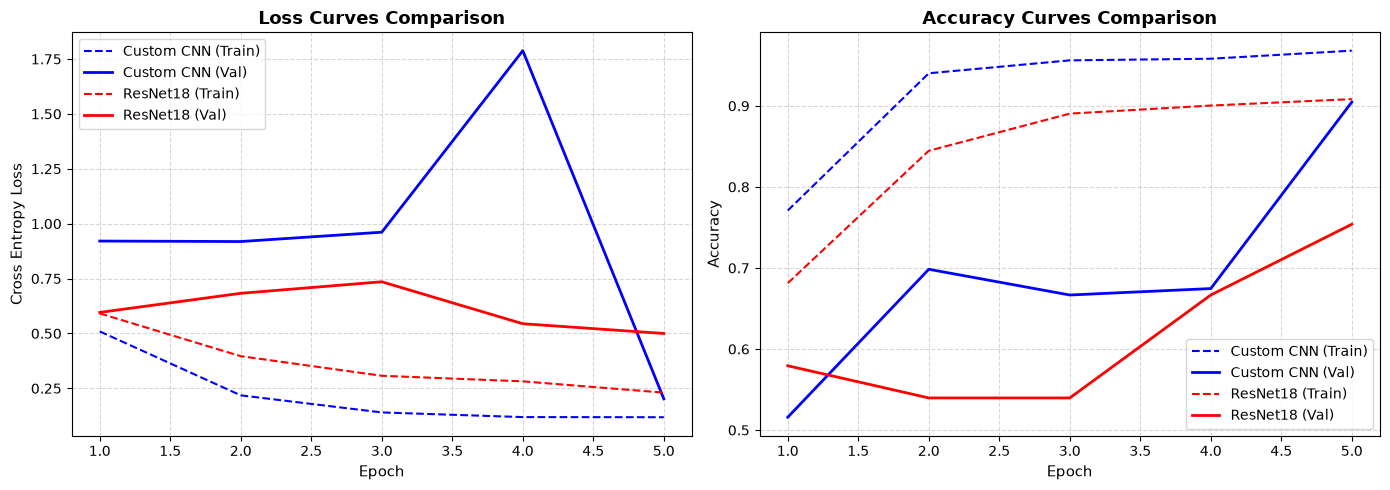

In [9]:
plot_training_comparison(hist_custom, hist_frozen)

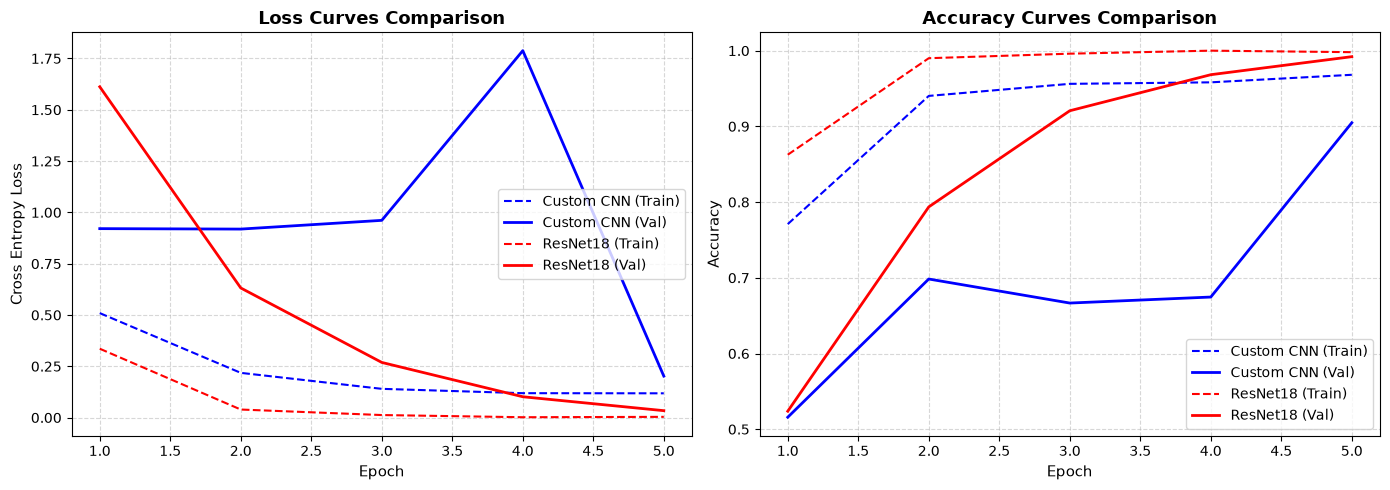

In [10]:
plot_training_comparison(hist_custom, hist_finetune)

### 2.4 Vyhodnocení metrik a Matice záměn (Confusion Matrix)

=== CustomCNN ===
Accuracy:  0.9048
Precision: 0.9811
Recall:    0.8254
F1-Score:  0.8966

=== RESNET18 ===
Accuracy:  0.9921
Precision: 1.0000
Recall:    0.9841
F1-Score:  0.9920


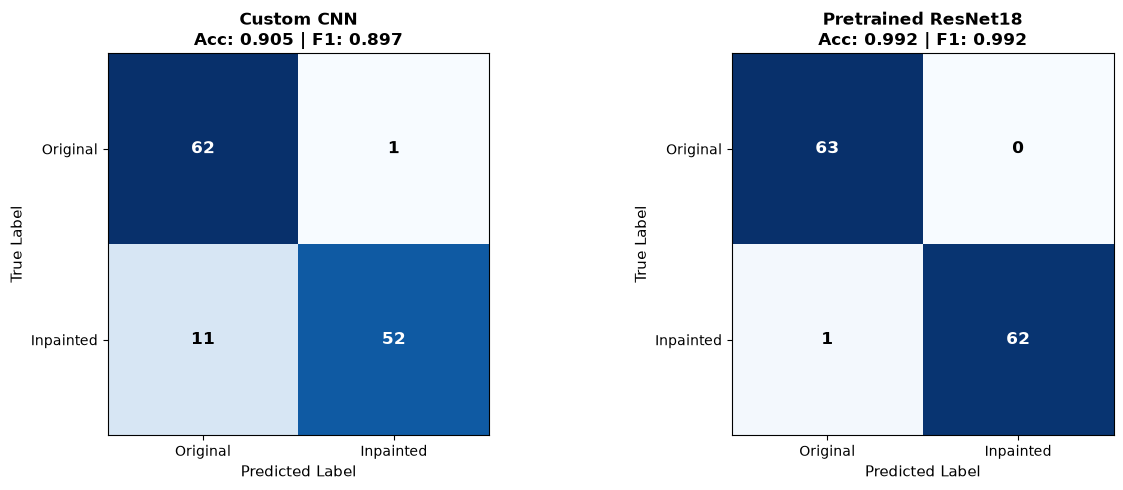

In [11]:
metrics_custom = compute_classification_metrics(custom_model, val_loader, device=device)
metrics_resnet = compute_classification_metrics(
    resnet_finetune, val_loader, device=device)

print("=== CustomCNN ===")
print(f"Accuracy:  {metrics_custom['accuracy']:.4f}")
print(f"Precision: {metrics_custom['precision']:.4f}")
print(f"Recall:    {metrics_custom['recall']:.4f}")
print(f"F1-Score:  {metrics_custom['f1']:.4f}")

print("\n=== RESNET18 ===")
print(f"Accuracy:  {metrics_resnet['accuracy']:.4f}")
print(f"Precision: {metrics_resnet['precision']:.4f}")
print(f"Recall:    {metrics_resnet['recall']:.4f}")
print(f"F1-Score:  {metrics_resnet['f1']:.4f}")

plot_confusion_matrices(metrics_custom, metrics_resnet)

## 3. Interpretovatelnost modelu (XAI)

Pro analýzu rozhodovacího procesu klasifikátoru aplikujeme tři metody atribuce příznaků:
1. **Grad-CAM (Gradient-weighted Class Activation Mapping):** Využívá gradienty výstupního skóre vzhledem k aktivačním mapám poslední konvoluční vrstvy pro lokalizaci oblastí, které vedly k rozhodnutí.
2. **Saliency Maps:** Vypočítává absolutní gradient výstupu vzhledem ke vstupním pixelům, čímž ukazuje lokální citlivost modelu na jednotlivé pixely.
3. **Integrated Gradients:** Axiomatická metoda integrující gradienty podél cesty mezi referenčním vstupem (baseline) a skutečným obrázkem.

### 3.1 XAI analýza pro model ResNet18
Vizualizace pro 2 originální a 2 inpaintované vzorky z validační sady.

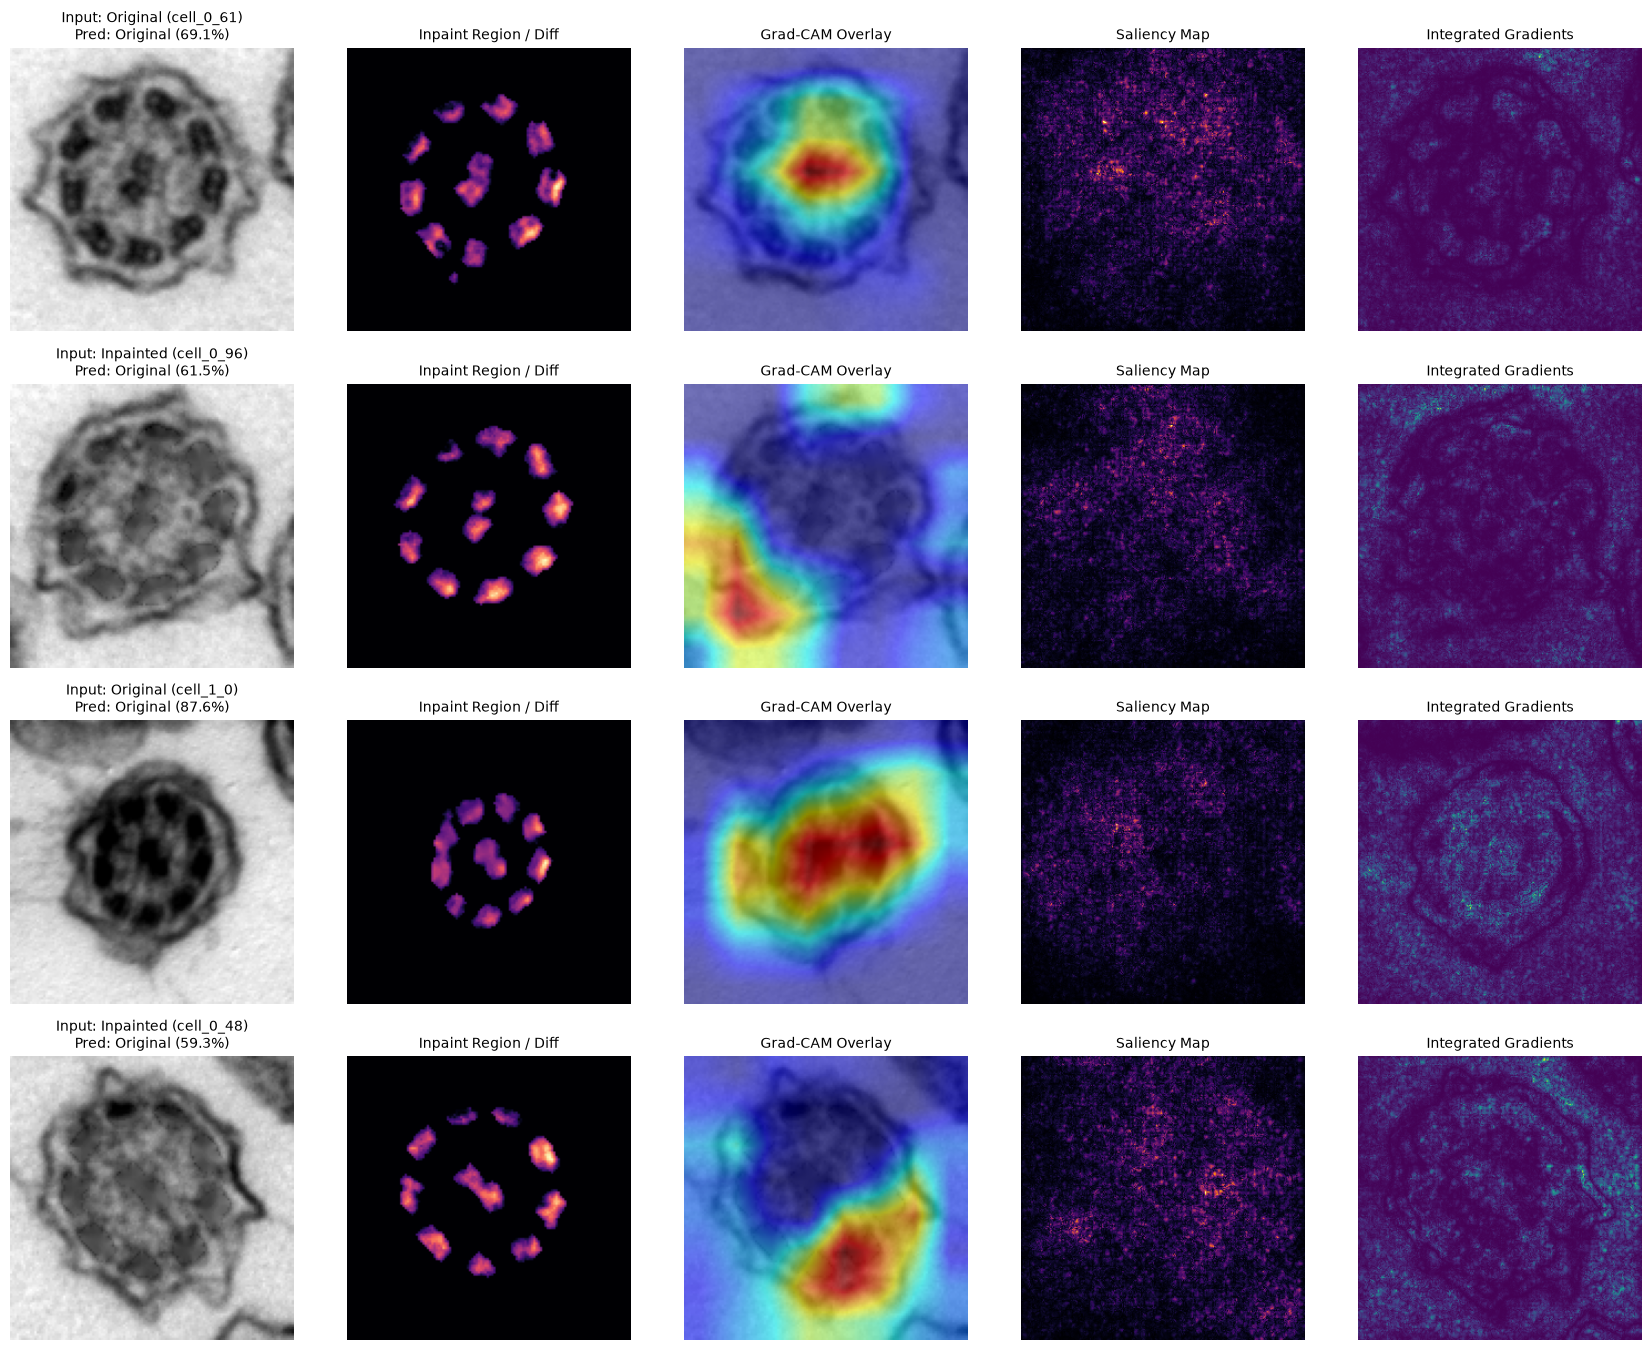

In [12]:
selected_samples = [val_data[i] for i in [0, 1, 2, 3]]

plot_xai_samples(
    resnet_frozen,
    selected_samples,
    target_layer=resnet_frozen.layer4[-1].conv2,
    img_size=256,
    device=device
)

### 3.2 XAI analýza pro vlastní CNN model
Srovnání atribučních map na vlastní navržené konvoluční síti.

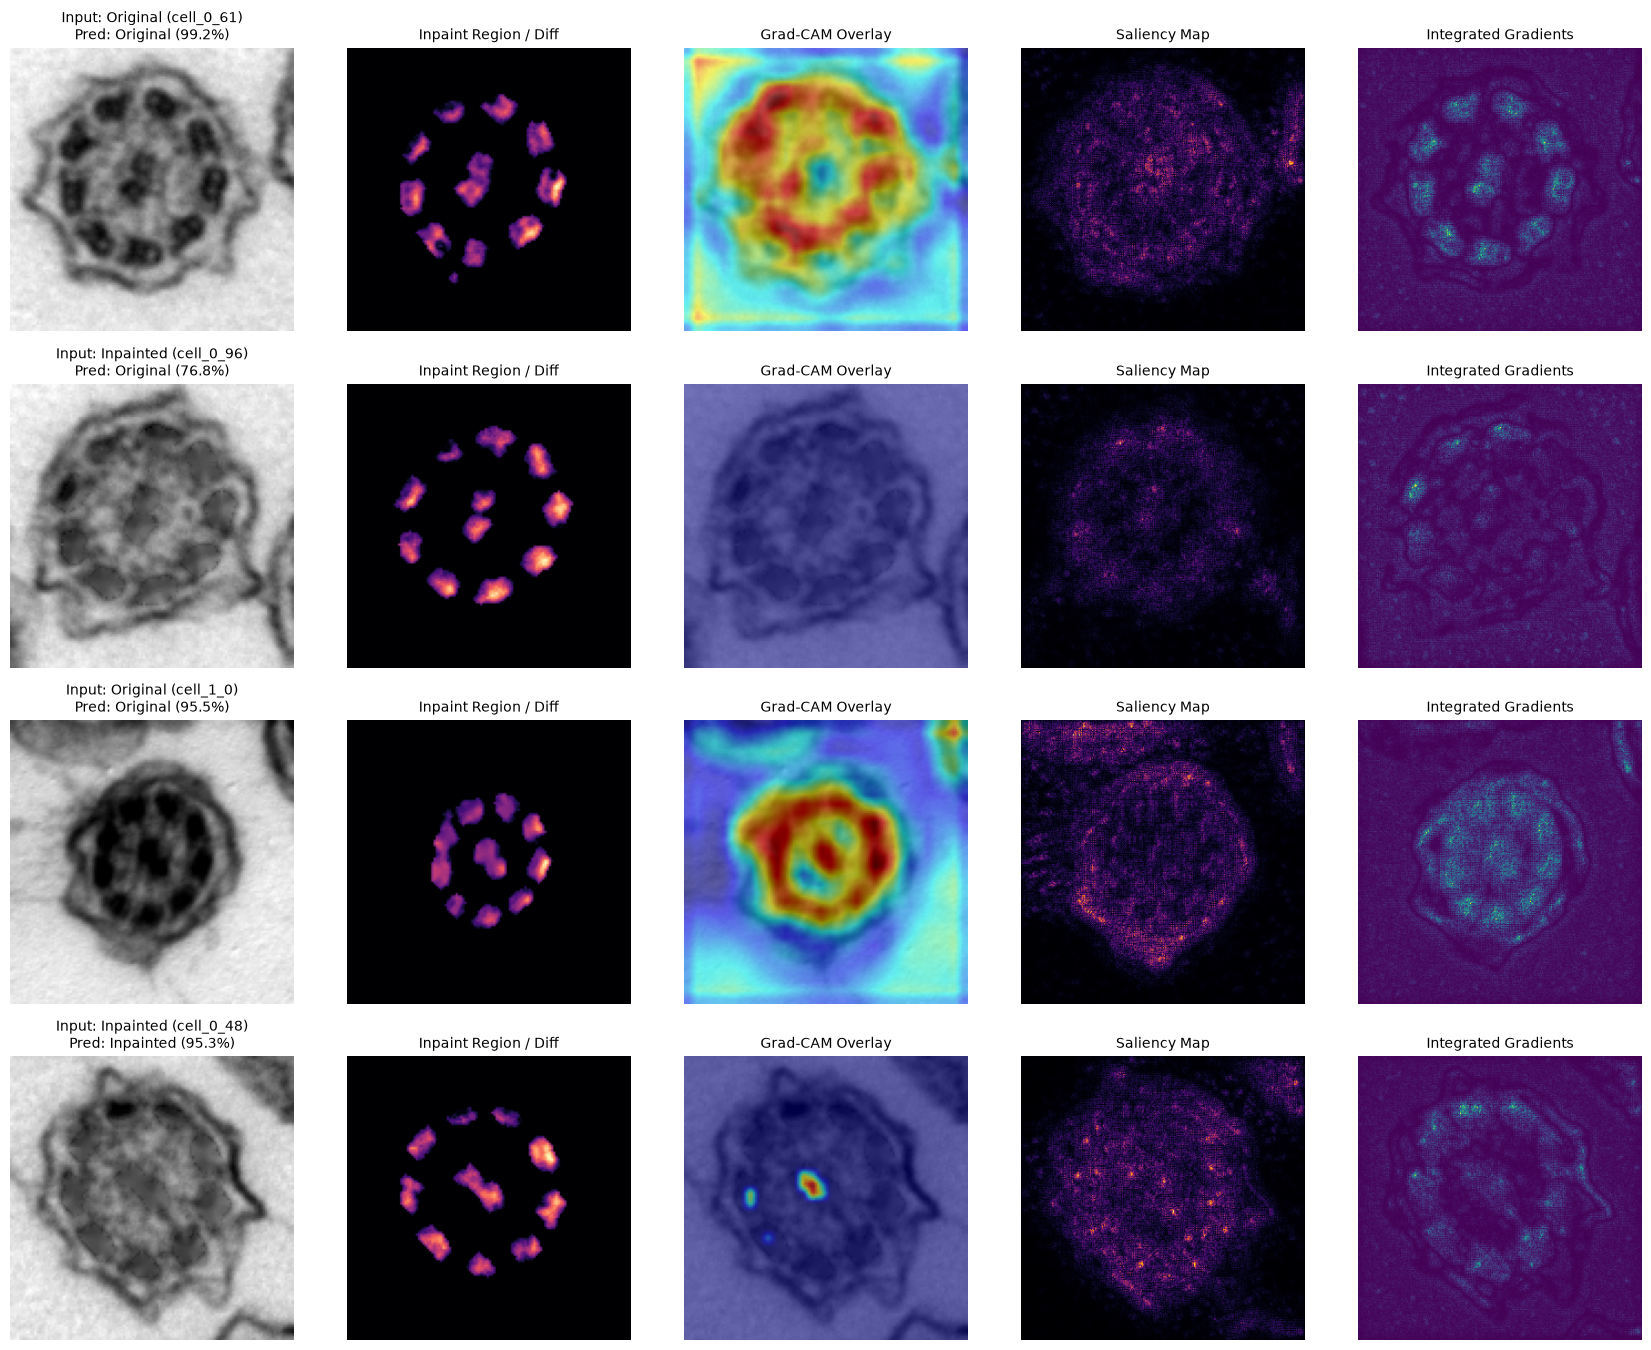

In [14]:
plot_xai_samples(
    custom_model,
    selected_samples,
    target_layer=custom_model.features[-1].block[0],
    img_size=256,
    device=device
)

## 4. Siamské sítě a měření podobnosti (Image Similarity)

Siamská síť se skládá ze dvou větví se **sdílenými vahami**, které mapují vstupní obrázky do L2-normalizovaného embeddingového prostoru.
- **Pozitivní páry (label = 1.0):** obrázky ze stejné třídy (originál-originál nebo inpaint-inpaint)
- **Negativní páry (label = 0.0):** obrázky z různých tříd (originál-inpaint)

K trénování se využívá **Contrastive Loss**:
$$\mathcal{L}(z_1, z_2, y) = \frac{1}{2} \left[ y \cdot D^2 + (1 - y) \cdot \max(0, m - D)^2 \right]$$
kde $D = \|z_1 - z_2\|_2$ je euklidovská vzdálenost a $m$ je margin (nastavený na 1.0).

In [15]:
train_pairs = generate_siamese_pairs(train_data, num_pairs=1000)
val_pairs = generate_siamese_pairs(val_data, num_pairs=300)

siamese_train_ds = SiameseDataset(train_pairs, img_size=256, augment=True)
siamese_val_ds = SiameseDataset(val_pairs, img_size=256, augment=False)

siamese_train_loader = DataLoader(siamese_train_ds, batch_size=32, shuffle=True)
siamese_val_loader = DataLoader(siamese_val_ds, batch_size=32, shuffle=False)

print(f"Train: {len(train_pairs)} (50% positive, 50% negative)")
print(f"Validation: {len(val_pairs)} (50% positive, 50% negative)")

Train: 1000 (50% positive, 50% negative)
Validation: 300 (50% positive, 50% negative)


### 4.1 Trénování Siamské sítě

In [16]:
siamese_model = SiameseNetwork(in_channels=3, embedding_dim=64).to(device)

hist_siamese = train_siamese_network(
    siamese_model,
    siamese_train_loader,
    siamese_val_loader,
    num_epochs=5,
    lr=1e-3,
    margin=1.0,
    device=device
)

Epoch  | Train Loss   | Val Loss     | Val Acc (tau=0.5)
-------------------------------------------------------
1      | 0.1450       | 0.1379       | 0.5367         
2      | 0.1386       | 0.1230       | 0.5933         
3      | 0.1311       | 0.1217       | 0.5667         
4      | 0.1225       | 0.0911       | 0.7533         
5      | 0.1090       | 0.1210       | 0.6267         


### 4.2 Vyhodnocení vzdáleností v embeddingovém prostoru
Zobrazení trénovací křivky a histogramů euklidovských vzdáleností pro pozitivní (podobné) a negativní (odlišné) páry na validačních datech.

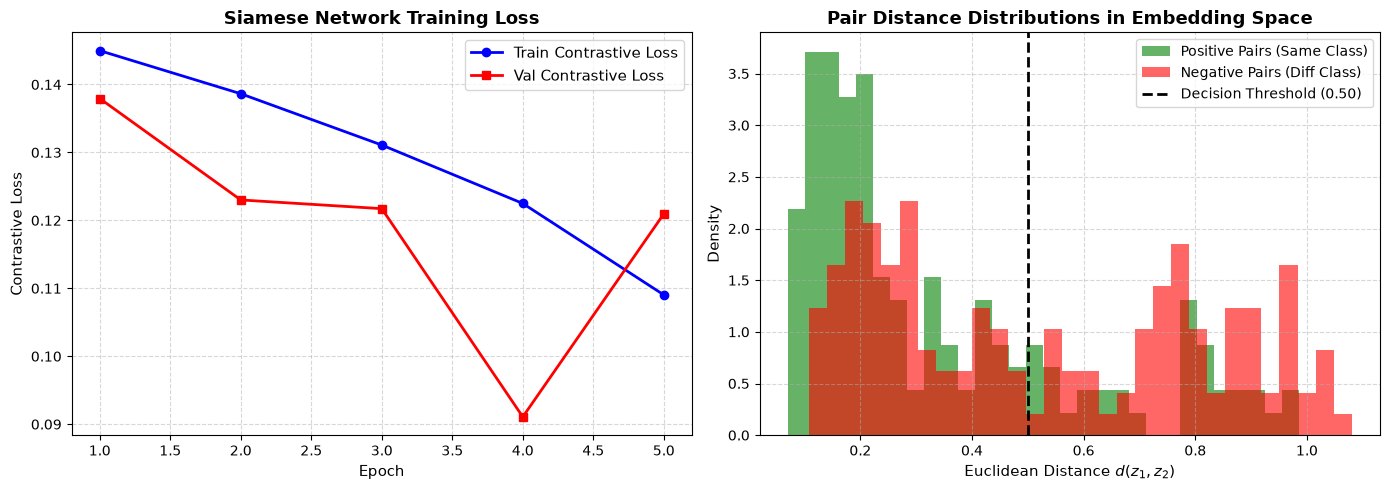

In [17]:
pos_dists, neg_dists = evaluate_siamese_distances(siamese_model, siamese_val_loader, device=device)
plot_siamese_results(hist_siamese, pos_dists, neg_dists, threshold=0.5)

### 4.3 2D projekce embeddingového prostoru (PCA)
Extrakce 64-dimenzionálních embeddingů pro validační vzorky a jejich redukce do 2D pomocí PCA.

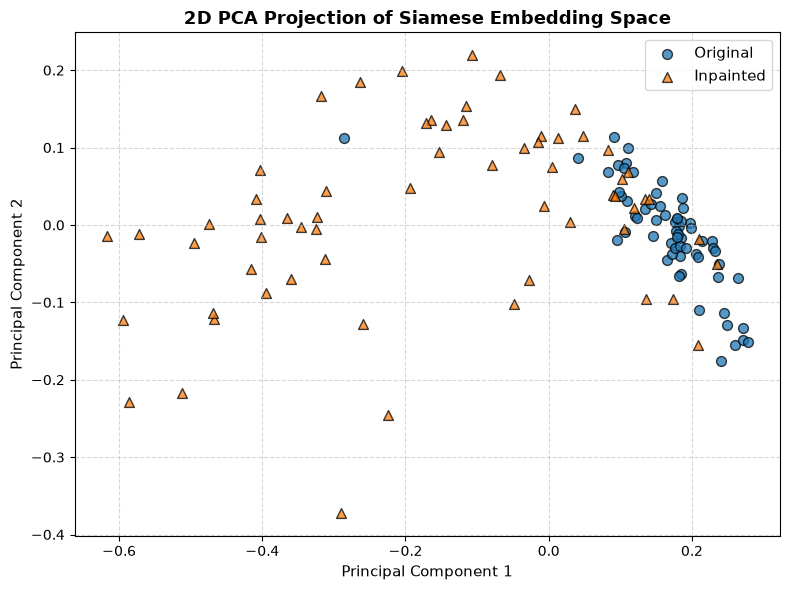

In [18]:
val_embeddings, val_labels = extract_embeddings(siamese_model, val_data, img_size=256, device=device)
plot_embedding_space_pca(val_embeddings, val_labels)

### 4.4 Ukázky predikcí podobnosti párů
Vizualizace konkrétních validačních dvojic a vyhodnocení jejich podobnosti na základě prahu vzdálenosti $\tau = 0.5$.

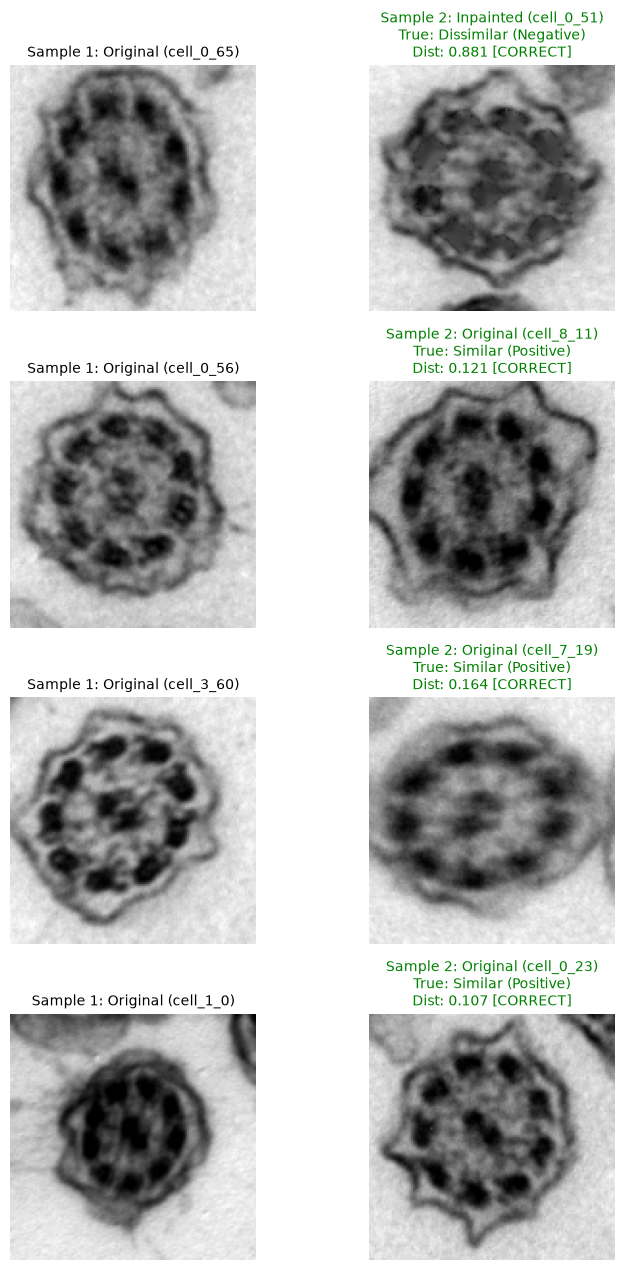

In [19]:
plot_siamese_pair_examples(
    siamese_model,
    val_pairs,
    num_examples=4,
    img_size=128,
    threshold=0.5,
    device=device
)